# V27: native packing headroom and conditional expert prior

H74changes only sum-token packing8192to10240; individual native4kinputs and
H60route/model recipe remain fixed. CPUgrouping evidence is not a GPU speedup
or probability-identity claim. H73's fixed60/40expert prior waits for actual
engineering success. [Plan](../docs/SPAN_027_PLAN.md) ·
[CPUproof](../docs/SPAN_027_CPU_PROOF.md) ·
[GPUprotocol](../docs/SPAN_027_GPU_PROTOCOL.md).

,packing_tokens,rows,tokens,micro_batches,mean_packed_tokens,peak_packed_tokens,max_sequence_tokens,peak_sum_squared_lengths
0,8192,57477,53256651,7368,7228.101384,8192,4330,29718244
1,10240,57477,53256651,5903,9021.963578,10240,4330,38385164


CPU elapsed seconds: 15.527045764960349 ; cap: 600
Fewer microbatches: 19.883279044516833 %; total input tokens unchanged: True
Full saved-length population uses synthetic payloads: True
Actual native reference streams verified separately; no full text retokenization or GPU/model output measurement.


,role,cohort,rows,old_microbatches,new_microbatches,new_peak_tokens,token_stream_exact
0,m0,warmup,80,9,7,9952,True
1,m0,control,256,33,27,10180,True
2,m0,uniform,512,67,53,10232,True
3,m0,long,64,63,32,8660,True
4,m0,test,3,1,1,2936,True
5,m3,warmup,80,9,7,10183,True
6,m3,control,256,33,27,10228,True
7,m3,uniform,512,65,52,10227,True
8,m3,long,64,63,32,8663,True
9,m3,test,3,1,1,2787,True


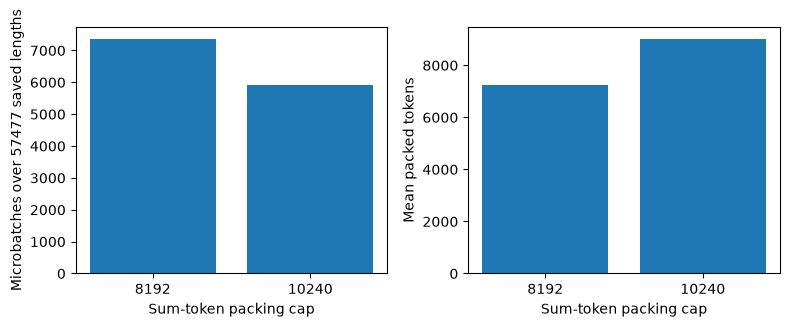

status.json {'status': 'COMPLETE', 'kernel_version': 'arseniytrushin/llm-preference-span027-native-packing/1', 'observed_at': '2026-11-08T20:53:17.528486+00:00'}
controller_state.json {'stage': 'complete', 'at': '2026-11-08T20:53:25.408632+00:00', 'pid': 1269591, 'role': 'packing_profile', 'status': 'COMPLETE', 'kernel_version': 'arseniytrushin/llm-preference-span027-native-packing/1', 'charged_seconds': 1107.563000000002, 'files': 23}
Engineering decision: stop_packing_guard ; H73allowed: False


{'role': 'm3',
 'cohort': 'control',
 'checks': {'ids_match': True,
  'lengths_match': True,
  'token_hash_match': True,
  'checkpoint_match': True,
  'memory_fractions': [0.5815348214173446, 0.512381882709452],
  'memory_passed': True,
  'canonical_rows': 256,
  'canonical_max_abs': 0.0003529191017150879,
  'canonical_passed': False,
  'passed': False},
 'official_submission_eligible': False}

Structural batching results do not establish a new competition score.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_027';r=json.loads((PUB/'packing_cpu_audit.json').read_text())
table=pd.DataFrame([{'packing_tokens':int(k),**{f:v[f] for f in ['rows','tokens','micro_batches','mean_packed_tokens','peak_packed_tokens','max_sequence_tokens','peak_sum_squared_lengths']}} for k,v in r['full_length_structure'].items()])
display(table)
print('CPU elapsed seconds:',r['elapsed_cpu_seconds'],'; cap:',r['cpu_cap_seconds'])
print('Fewer microbatches:',100*r['micro_batch_reduction_fraction'],'%; total input tokens unchanged:',r['total_input_tokens_unchanged'])
print('Full saved-length population uses synthetic payloads:',r['full_length_payload_is_synthetic'])
print('Actual native reference streams verified separately; no full text retokenization or GPU/model output measurement.')
cohorts=[]
for role,values in r['actual_native_reference_cohorts'].items():
 for name,variants in values.items():
  a,b=variants['8192'],variants['10240']
  cohorts.append({'role':role,'cohort':name,'rows':b['rows'],'old_microbatches':a['micro_batches'],'new_microbatches':b['micro_batches'],
   'new_peak_tokens':b['peak_packed_tokens'],'token_stream_exact':a['token_stream_sha256']==b['token_stream_sha256']})
display(pd.DataFrame(cohorts))
fig,axes=plt.subplots(1,2,figsize=(8,3.2))
axes[0].bar(table.packing_tokens.astype(str),table.micro_batches);axes[0].set_ylabel('Microbatches over 57477 saved lengths')
axes[1].bar(table.packing_tokens.astype(str),table.mean_packed_tokens);axes[1].set_ylabel('Mean packed tokens')
for ax in axes:ax.set_xlabel('Sum-token packing cap')
fig.tight_layout();ROOT=Path.home()/'database/llm_classification_finetuning/runs/span_027'
(ROOT/'figures').mkdir(exist_ok=True);fig.savefig(ROOT/'figures/packing_structure.png',dpi=160,bbox_inches='tight');plt.show()
job=PUB/'jobs/packing_profile'
for name in ['status.json','controller_state.json']:
 path=job/name
 if path.exists():print(name,json.loads(path.read_text()))
decision=PUB/'profile_audit.json'
if decision.exists():
 result=json.loads(decision.read_text());print('Engineering decision:',result['decision'],'; H73allowed:',result['engineering_gate_passed'])
 if 'guard_failure' in result:display(result['guard_failure'])
 if 'runtime' in result:display(result['runtime'])
else:print('GPU probability identity, memory and runtime qualification are pending.')
print('Structural batching results do not establish a new competition score.')

In [2]:
description=PUB/'failure_description.json'
if description.exists():
 d=json.loads(description.read_text())
 display(pd.DataFrame([{'cohort':k,**{f:v[f] for f in ['rows','max_abs','mean_abs','rows_above_original_tolerance','argmax_changes']}} for k,v in d['cohorts'].items()]))
 print(d['interpretation'])
 print('No target labels read; no quality measured; no new GPU execution.')
if decision.exists() and not result['engineering_gate_passed']:
 print('H74 failed. H73 deferred without computing the fixed 60/40 mixture. No new official submission.')
state=job/'controller_state.json'
if state.exists():print('Controller terminal evidence:',json.loads(state.read_text()))
inventory=PUB/'terminal_inventory.json'
if inventory.exists():
 inv=json.loads(inventory.read_text());print('Nonterminal owned jobs:',len(inv['nonterminal_jobs']));print('Quota:',inv['quota'])
board=PUB/'final_leaderboard.json'
if board.exists():print('Complete official board:',json.loads(board.read_text()))

,cohort,rows,max_abs,mean_abs,rows_above_original_tolerance,argmax_changes
0,m0_control,256,0.000000,0.000000,0,0
1,m0_long,64,0.000072,0.000002,4,0
2,m0_test,3,0.000000,0.000000,0,0
3,m0_uniform,512,0.000492,0.000003,14,0
4,m0_warmup,80,0.000000,0.000000,0,0
5,m3_control,256,0.000353,0.000005,12,0
6,m3_warmup,80,0.000000,0.000000,0,0


Probability drift is observed. Its cause and quality effect are unmeasured; unchanged argmax does not establish equivalent log loss.
No target labels read; no quality measured; no new GPU execution.
H74 failed. H73 deferred without computing the fixed 60/40 mixture. No new official submission.
Controller terminal evidence: {'stage': 'complete', 'at': '2026-11-08T20:53:25.408632+00:00', 'pid': 1269591, 'role': 'packing_profile', 'status': 'COMPLETE', 'kernel_version': 'arseniytrushin/llm-preference-span027-native-packing/1', 'charged_seconds': 1107.563000000002, 'files': 23}
Nonterminal owned jobs: 0
Quota: {'used_seconds': 29919.217, 'reserved_seconds': 0.0, 'allowed_seconds': 108000.0, 'refresh_time': '2026-11-14 00:00:00', 'paid_scaling': False, 'remaining_seconds': 78080.783}
Complete official board: {'observed_at': '2026-11-08T20:55:30.572798+00:00', 'complete': True, 'team_id': 17244411, 'rank': 23, 'teams': 310, 'score': 0.82987, 'rank19_score': 0.82915, 'rank20_score': 0.82915, 